In [3]:
import os
for root, dirs, files in os.walk('/kaggle/input'):
    if files:
        print(root, "->", len(files), "images")

In [4]:
import tensorflow as tf
from tensorflow.keras import layers, models

base = r"D:\fruits\archive\dataset"   # upar wale output se badlo
train_dir = base + '/train'
test_dir  = base + '/test'

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir, image_size=(224, 224), batch_size=32,
    validation_split=0.2, subset='training', seed=42)
val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir, image_size=(224, 224), batch_size=32,
    validation_split=0.2, subset='validation', seed=42)
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir, image_size=(224, 224), batch_size=32, shuffle=False)

class_names = train_ds.class_names
print(class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds   = val_ds.cache().prefetch(AUTOTUNE)

Found 10901 files belonging to 6 classes.
Using 8721 files for training.
Found 10901 files belonging to 6 classes.
Using 2180 files for validation.
Found 2698 files belonging to 6 classes.
['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges']


In [5]:
aug = tf.keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomBrightness(0.1),
])

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base_model.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))
x = aug(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(6, activation='softmax')(x)

model = models.Model(inputs, outputs)
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [6]:
ckpt = tf.keras.callbacks.ModelCheckpoint(
    r"D:\fruits\fruit_model.keras", save_best_only=True,
    monitor='val_accuracy')

history = model.fit(train_ds, validation_data=val_ds,
                    epochs=5, callbacks=[ckpt])

Epoch 1/5


d:\fruits\tfenv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


273/273 ━━━━━━━━━━━━━━━━━━━━ 226s 802ms/step - accuracy: 0.8991 - loss: 0.3138 - val_accuracy: 0.9688 - val_loss: 0.1094
Epoch 2/5
273/273 ━━━━━━━━━━━━━━━━━━━━ 6031s 22s/step - accuracy: 0.9718 - loss: 0.0989 - val_accuracy: 0.9780 - val_loss: 0.0725
Epoch 3/5
273/273 ━━━━━━━━━━━━━━━━━━━━ 324s 1s/step - accuracy: 0.9779 - loss: 0.0735 - val_accuracy: 0.9817 - val_loss: 0.0596
Epoch 4/5
273/273 ━━━━━━━━━━━━━━━━━━━━ 348s 1s/step - accuracy: 0.9814 - loss: 0.0622 - val_accuracy: 0.9858 - val_loss: 0.0483
Epoch 5/5
273/273 ━━━━━━━━━━━━━━━━━━━━ 284s 1s/step - accuracy: 0.9805 - loss: 0.0570 - val_accuracy: 0.9872 - val_loss: 0.0428


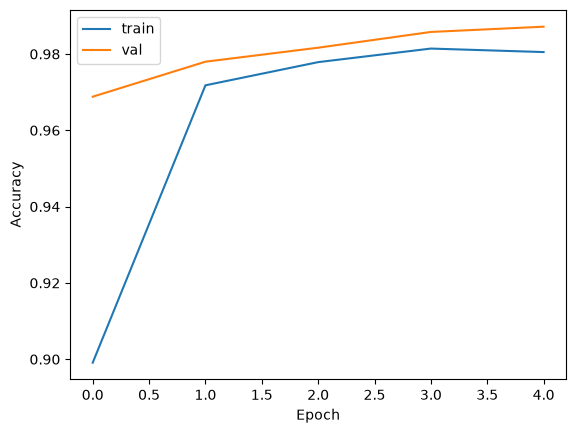

In [7]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.show()

In [8]:
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test accuracy: {test_acc*100:.2f}%")

85/85 ━━━━━━━━━━━━━━━━━━━━ 48s 558ms/step - accuracy: 0.9855 - loss: 0.0483
Test accuracy: 98.55%


85/85 ━━━━━━━━━━━━━━━━━━━━ 48s 566ms/step
               precision    recall  f1-score   support

  freshapples       0.98      0.98      0.98       395
  freshbanana       1.00      1.00      1.00       381
 freshoranges       1.00      0.95      0.97       388
 rottenapples       0.99      0.99      0.99       601
 rottenbanana       1.00      1.00      1.00       530
rottenoranges       0.95      0.99      0.97       403

     accuracy                           0.99      2698
    macro avg       0.99      0.98      0.98      2698
 weighted avg       0.99      0.99      0.99      2698



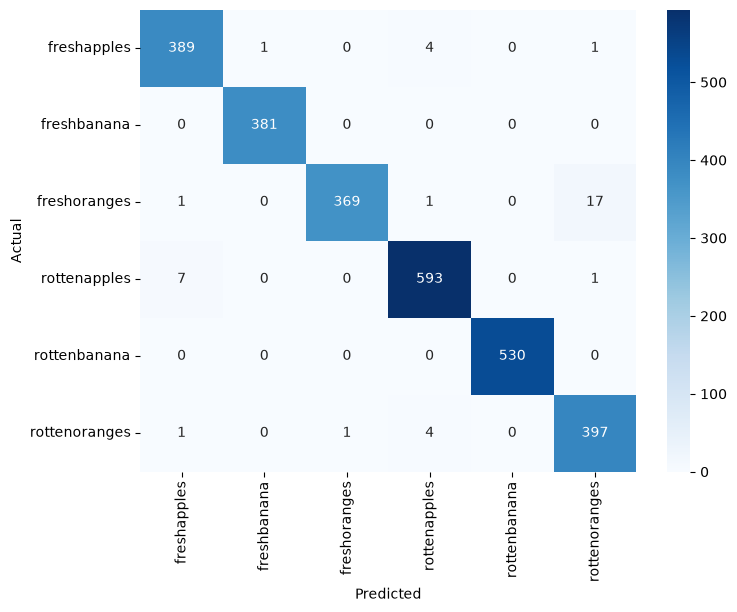

In [11]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt



y_true = np.concatenate([y.numpy() for x, y in test_ds])
y_pred = np.argmax(model.predict(test_ds), axis=1)

print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.show()

In [11]:
model.save(r"D:\fruits\fruit_model.keras")

In [12]:


import gradio as gr
import numpy as np

class_names = ['freshapples','freshbanana','freshoranges',
               'rottenapples','rottenbanana','rottenoranges']

def predict(img):
    img = tf.image.resize(img, (224, 224))
    img = tf.expand_dims(img, 0)
    probs = model.predict(img)[0]
    return {class_names[i]: float(probs[i]) for i in range(6)}

gr.Interface(fn=predict,
             inputs=gr.Image(),
             outputs=gr.Label(num_top_classes=3),
             title="Fruit Freshness Classifier").launch(share=True)

d:\fruits\tfenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


* Running on local URL:  http://127.0.0.1:7860

Could not create share link. Please check your internet connection or our status page: https://status.gradio.app.


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


In [ ]:
#import sys, tensorflow as tf
#print(sys.executable)
#print(tf.__version__)

d:\fruits\tfenv\Scripts\python.exe
2.21.0


In [ ]:
#import os
#for root, dirs, files in os.walk(r"D:\fruits\archive"):
    #if 'train' in dirs and 'test' in dirs:
       # print(root)

D:\fruits\archive\dataset
D:\fruits\archive\dataset\dataset


In [13]:
import tensorflow as tf
print(tf.config.list_physical_devices('GPU'))

[]
